In [1]:
import sys
sys.path.append("/hlabhome/wg-mjames/git/Toby_work")
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import ks_2samp
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
from collections import Counter
from threadpoolctl import threadpool_info, threadpool_limits
%load_ext autoreload
%autoreload 2
import os
NCPU = "4"
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

# Loading and Generating Train/Test Datasets

Currently the main dataset that everything draws from is "filtered_full_animal_isi.pkl" in Toby_Work/sleep_indiv_neuron, though this can be changed by passing a different base_path to generate_train_test_dataset() at the start of everything. Below is an example of loading an unfiltered train/test dataset split into 500 ISI chunks

In [2]:
#This dictates where your train/test split occurs, in this case 60% to 80% of the dataset
split_thres = (0.6, 0.8)
#This determines if you are doing additional downsampling of some kind to compensate for sleep structure differences
#Acceptable ones are 'downisi' which filters down to a matching isi ratio for all neurons, 'downisitime' whcih filters
# down to a matching time ratio for all neurons, and 'downisiset' which filters down to the specified downlims for
# every neuron, excluding ones that don't meet the minimum requirements. Any other string will result in no downsampling
# This is also treated as a name for saving scaled train/test data in the scaled_sets folder, which allows for time saving.
addon = 'unfiltered'
#Only used if addon=='downisiset', amount of NREM, REM, and Wake chunks each neuron trains on respectively
downlims = [10,4,10]
#Specifies where to begin specific downsampling from proportionally, i.e. if you are downsampling with downisiset to 
#5 NREM chunks, but a neuron has 40 NREM chunks, a "starting_from" of zero will collect chunks 0-4, while a 
#"starting_from" of 0.4 will collect chunks 16-20 for training purpose. Allows for better coverage. 
starting_from = 0.4
#Specifies whether you are trying to load a scaled set that may already exist. The only time this should be
#false is if you know a scaled set is incorrect/lacking information, and you are going to overwrite it with
#a fresh generation. Please note that if you are trying to generate a split with a different isi chunk number than 500,
# DO NOT attempt to load data or save it, this is all set up without splitting_number in the filenames, so
# you will not get the data you want.
load_data = True
#Whether it will overwrite a previous scaled set when trying to save if there is one present
overwrite=False
#If it will generate a new train/test split if there isn't a matching one saved already
generate_if_failed=True
#If it will save the data after generating a fresh set. If overwrite is False and one already exists,
#it will not save to prevent overwriting.
save_data_after = True
train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, 
                                                          downlims,starting_from=starting_from,
                                                         generate_if_failed=generate_if_failed,
                                                         save_data_after=save_data_after)

Loaded successfully


In [3]:
#Example of getting a dataset downsampled to 5,3,5 chunks from 40%-60%, with defaults left this time
split_thres = (0.4, 0.6)
addon = 'downisiset'
downlims = [5,3,5]
load_data=True
train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, 
                                                          downlims)

Loaded successfully


# Getting a Condensed Dataset/Final Alterations Before Training
Before models get trained on all of this, change the dataset if you are hoping to do some shenanigans with
2 state classifiers, and also grab a condensed dataset that will help a bunch of visuals later

In [6]:
#This is effectively used for grouping neurons by various aspects like region, age, genotype, etc,
#with one row per neuron per sleep state. It provides additional information about the number of sleep chunks
#each neuron used for training as well, which some graphics utilize. Looking at it is a good way to check that
#downsampling was successful, since 'downisiset' should make every neuron present have the same number of each chunk
train_condensed = get_extended_condensed_data(train_scaled)

In [4]:
#If you want to look at sleep v wake, make a separate train/test set for s/w by converting rem to nrem effectively
sw_train_scaled = get_sleep_state_conversion(train_scaled)
sw_test_scaled = get_sleep_state_conversion(test_scaled)
sw_train_condensed = get_extended_condensed_data(sw_train_scaled)

# Training Your Models!
Now the models get trained on the scaled data from before. Specify the types of sampling and the methods you want. The valid options for sampling are over, under, smote (which frequently fails due to low numbers of rem samples, I only really use it for s/w stuff if I really want to, though oversampling works about as well), and balanced (though I haven't tested this one really). As for methods, 'LogReg' = logistic_by_cell, so per neuron, 'XGBoost' = xgb_by_cell, so per neuron, and 'LogRegGroup' = logistic_by_grouping, which is more complicated and explained later.

In [5]:
#This trains 4 model sets, LogReg_over, LogReg_under, XGBoost_over, and XGBoost_under. LogReg models take about 
#1-2 minutes to fit, while XGBoost ones take about 5-10 minutes (and aren't that good really)
nrw_models = train_multi_models(train_scaled, sampling_types=['over', 'under'], methods=['LogReg', 'XGBoost'])
#Get sleep v wake classifiers with the converted train_scale data from earlier. Set num_states to 2 to match state count
sw_models = train_multi_models(sw_train_scaled, sampling_types=['under'], methods=['LogReg'],
                              num_states=2)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [00:27<00:00, 159.43it/s]


# Getting Confusion Matrices/Testing
Now you actually have to test the models on your specified testing data from earlier.
This simply goes through every model set in the provided models and generates a confusion matrix for everything after
matching the model to its appropriate testing data. get_spiking tacks on a bunch of informative arrays to the confusion matrices including real states, predictions, prediction confidences, the number of spikes in that chunk, the total number of spikes in that state, as well as timing data if include_timing is True. This information isn't necessary unless you want it and/or are looking at confidence metrics for the models. For basic performance graphics it's not required. Some of the saved scaled sets are from before I added timing data to the overall dataset, so trying to include it will crash it. You only need timing data for full-animal majority vote stuff though (for chunk alignment) so this generally isn't a problem. 

In [7]:
cms = get_cms_multi(test_scaled, nrw_models, get_spiking=True, include_timing=False)
sw_cms = get_cms_multi(sw_test_scaled, sw_models)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [00:12<00:00, 333.44it/s]


# Visualizing the Average Performance
Now that you have the confusion matrices, you can visualize it in a multitude of ways. The two main ones I default to are the get_mean_cms_visual() and get_cm_distrib_hist() to visualize average confusion matrix performance, as well as the distribution of model accuracies compared to chance

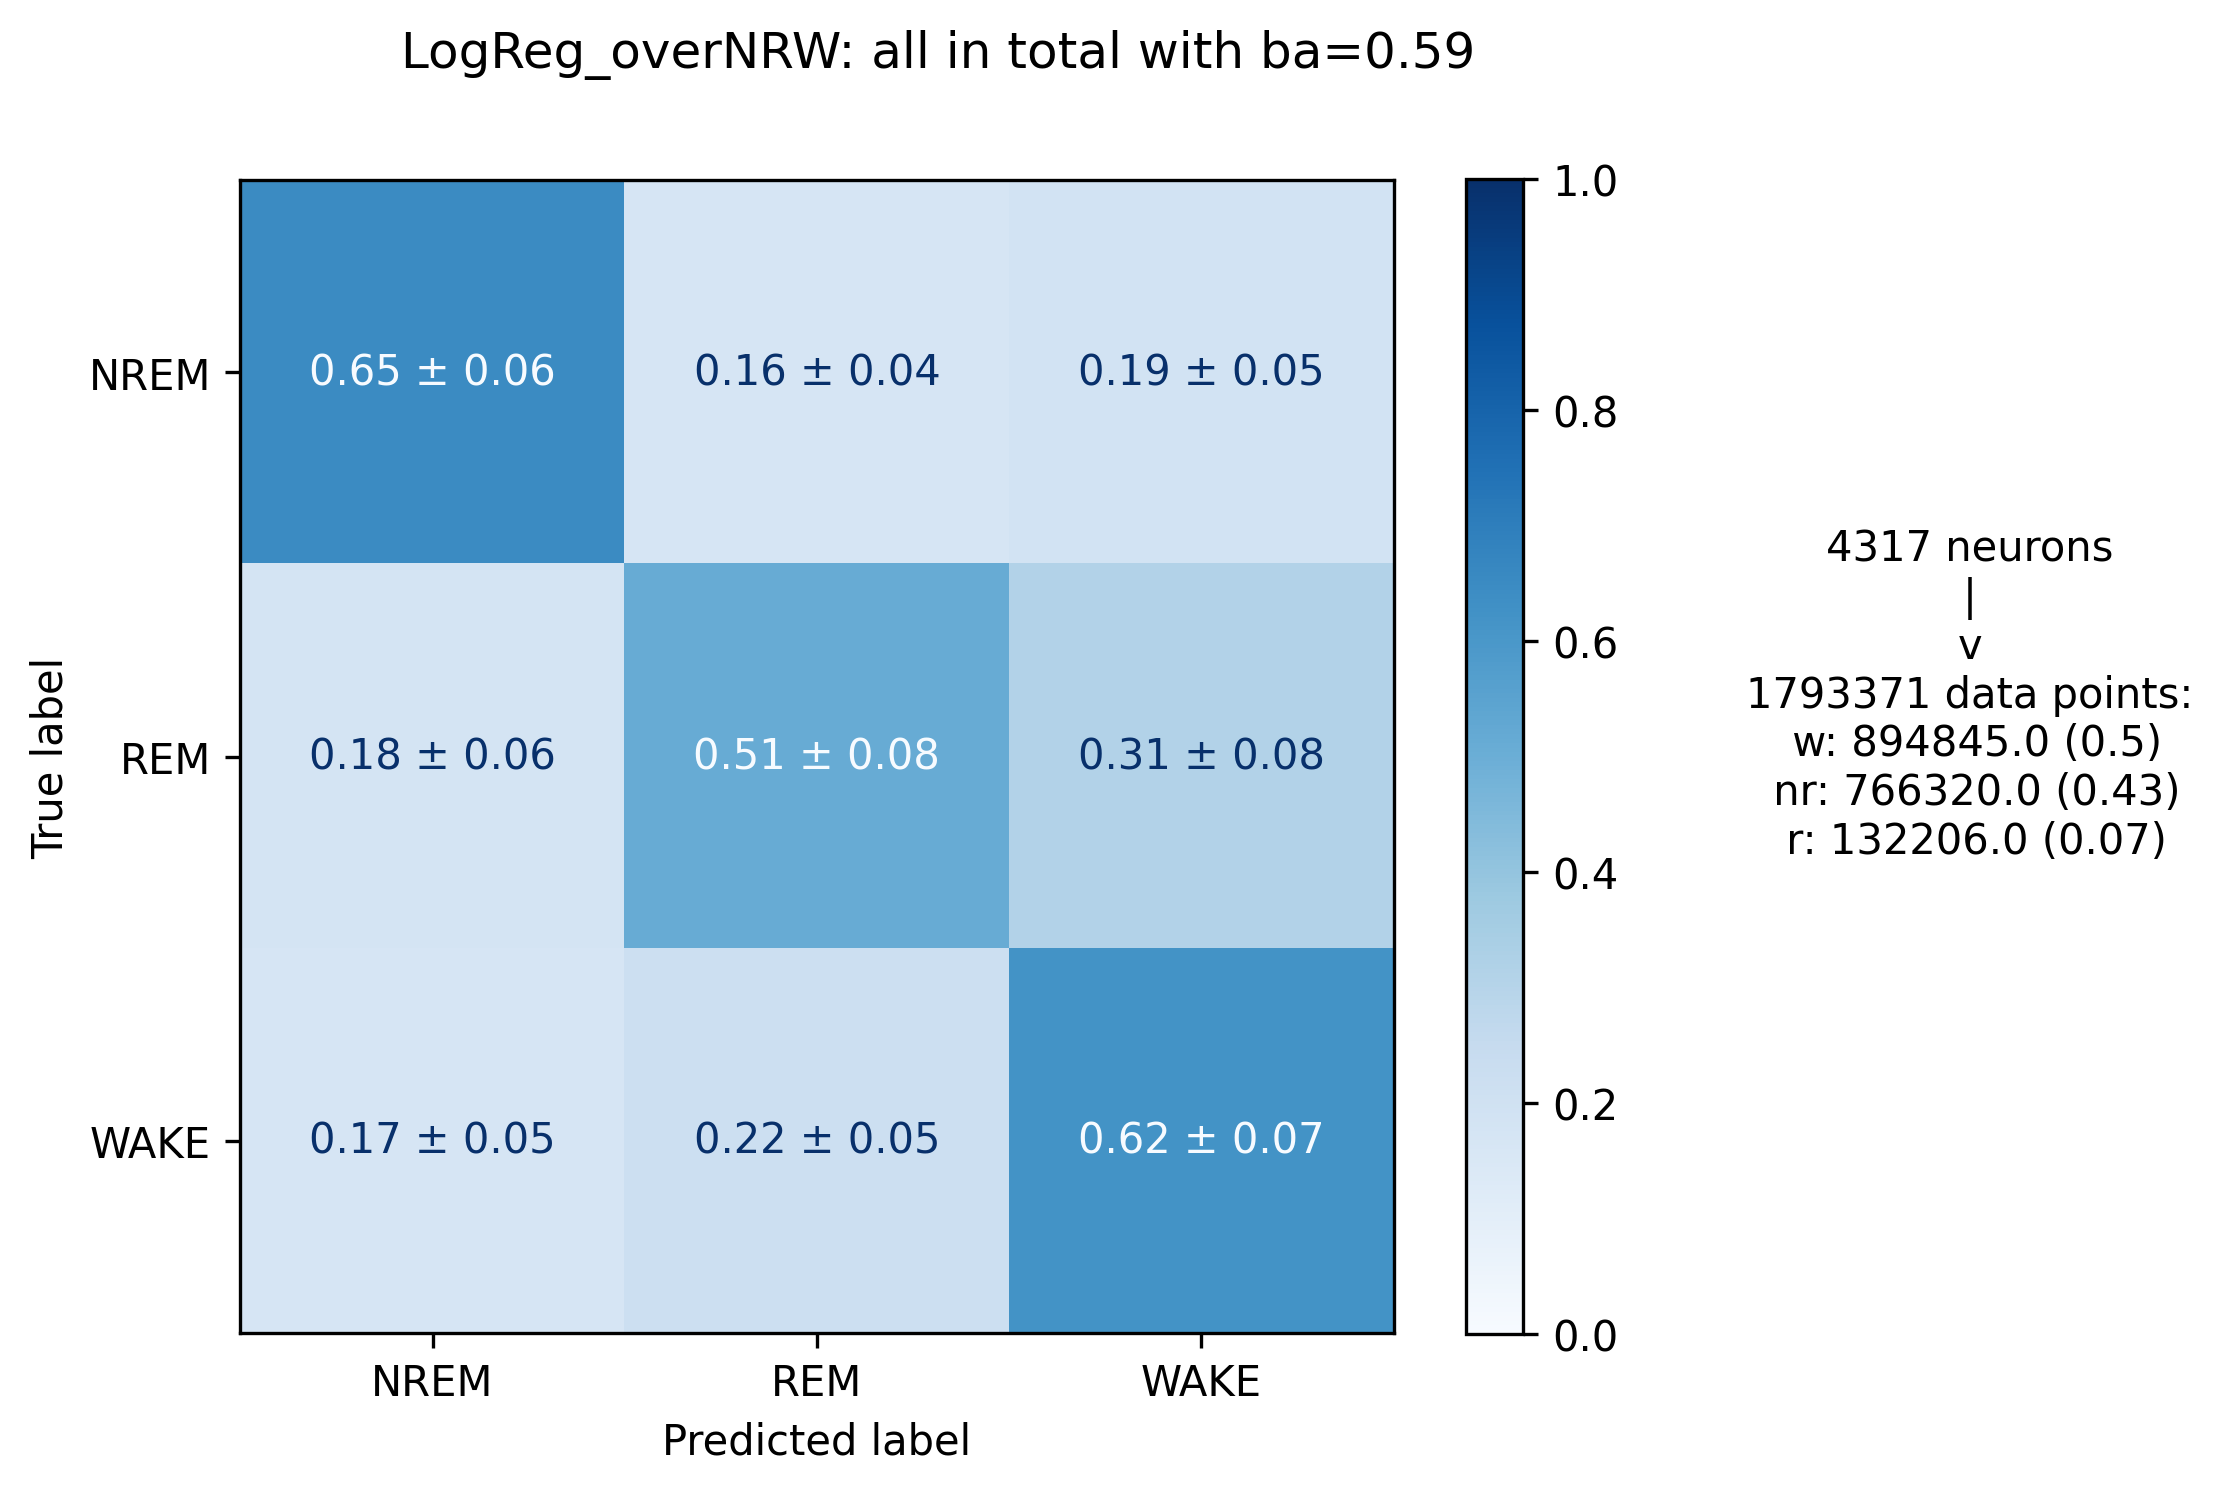

In [9]:
for model_name, matrices in cms.items():
    #Subplot_kwargs passes on kwargs you want in plt.subplots(), use a 1.25:1 ratio to have everything line up well
    #Addon_text determines if the text to the right is included.
    #se, sd, and alt_se determine what kind of +- you want.
    get_mean_cms_visual(matrices, train_condensed, f"{model_name}NRW", subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=True, alt_se=True)

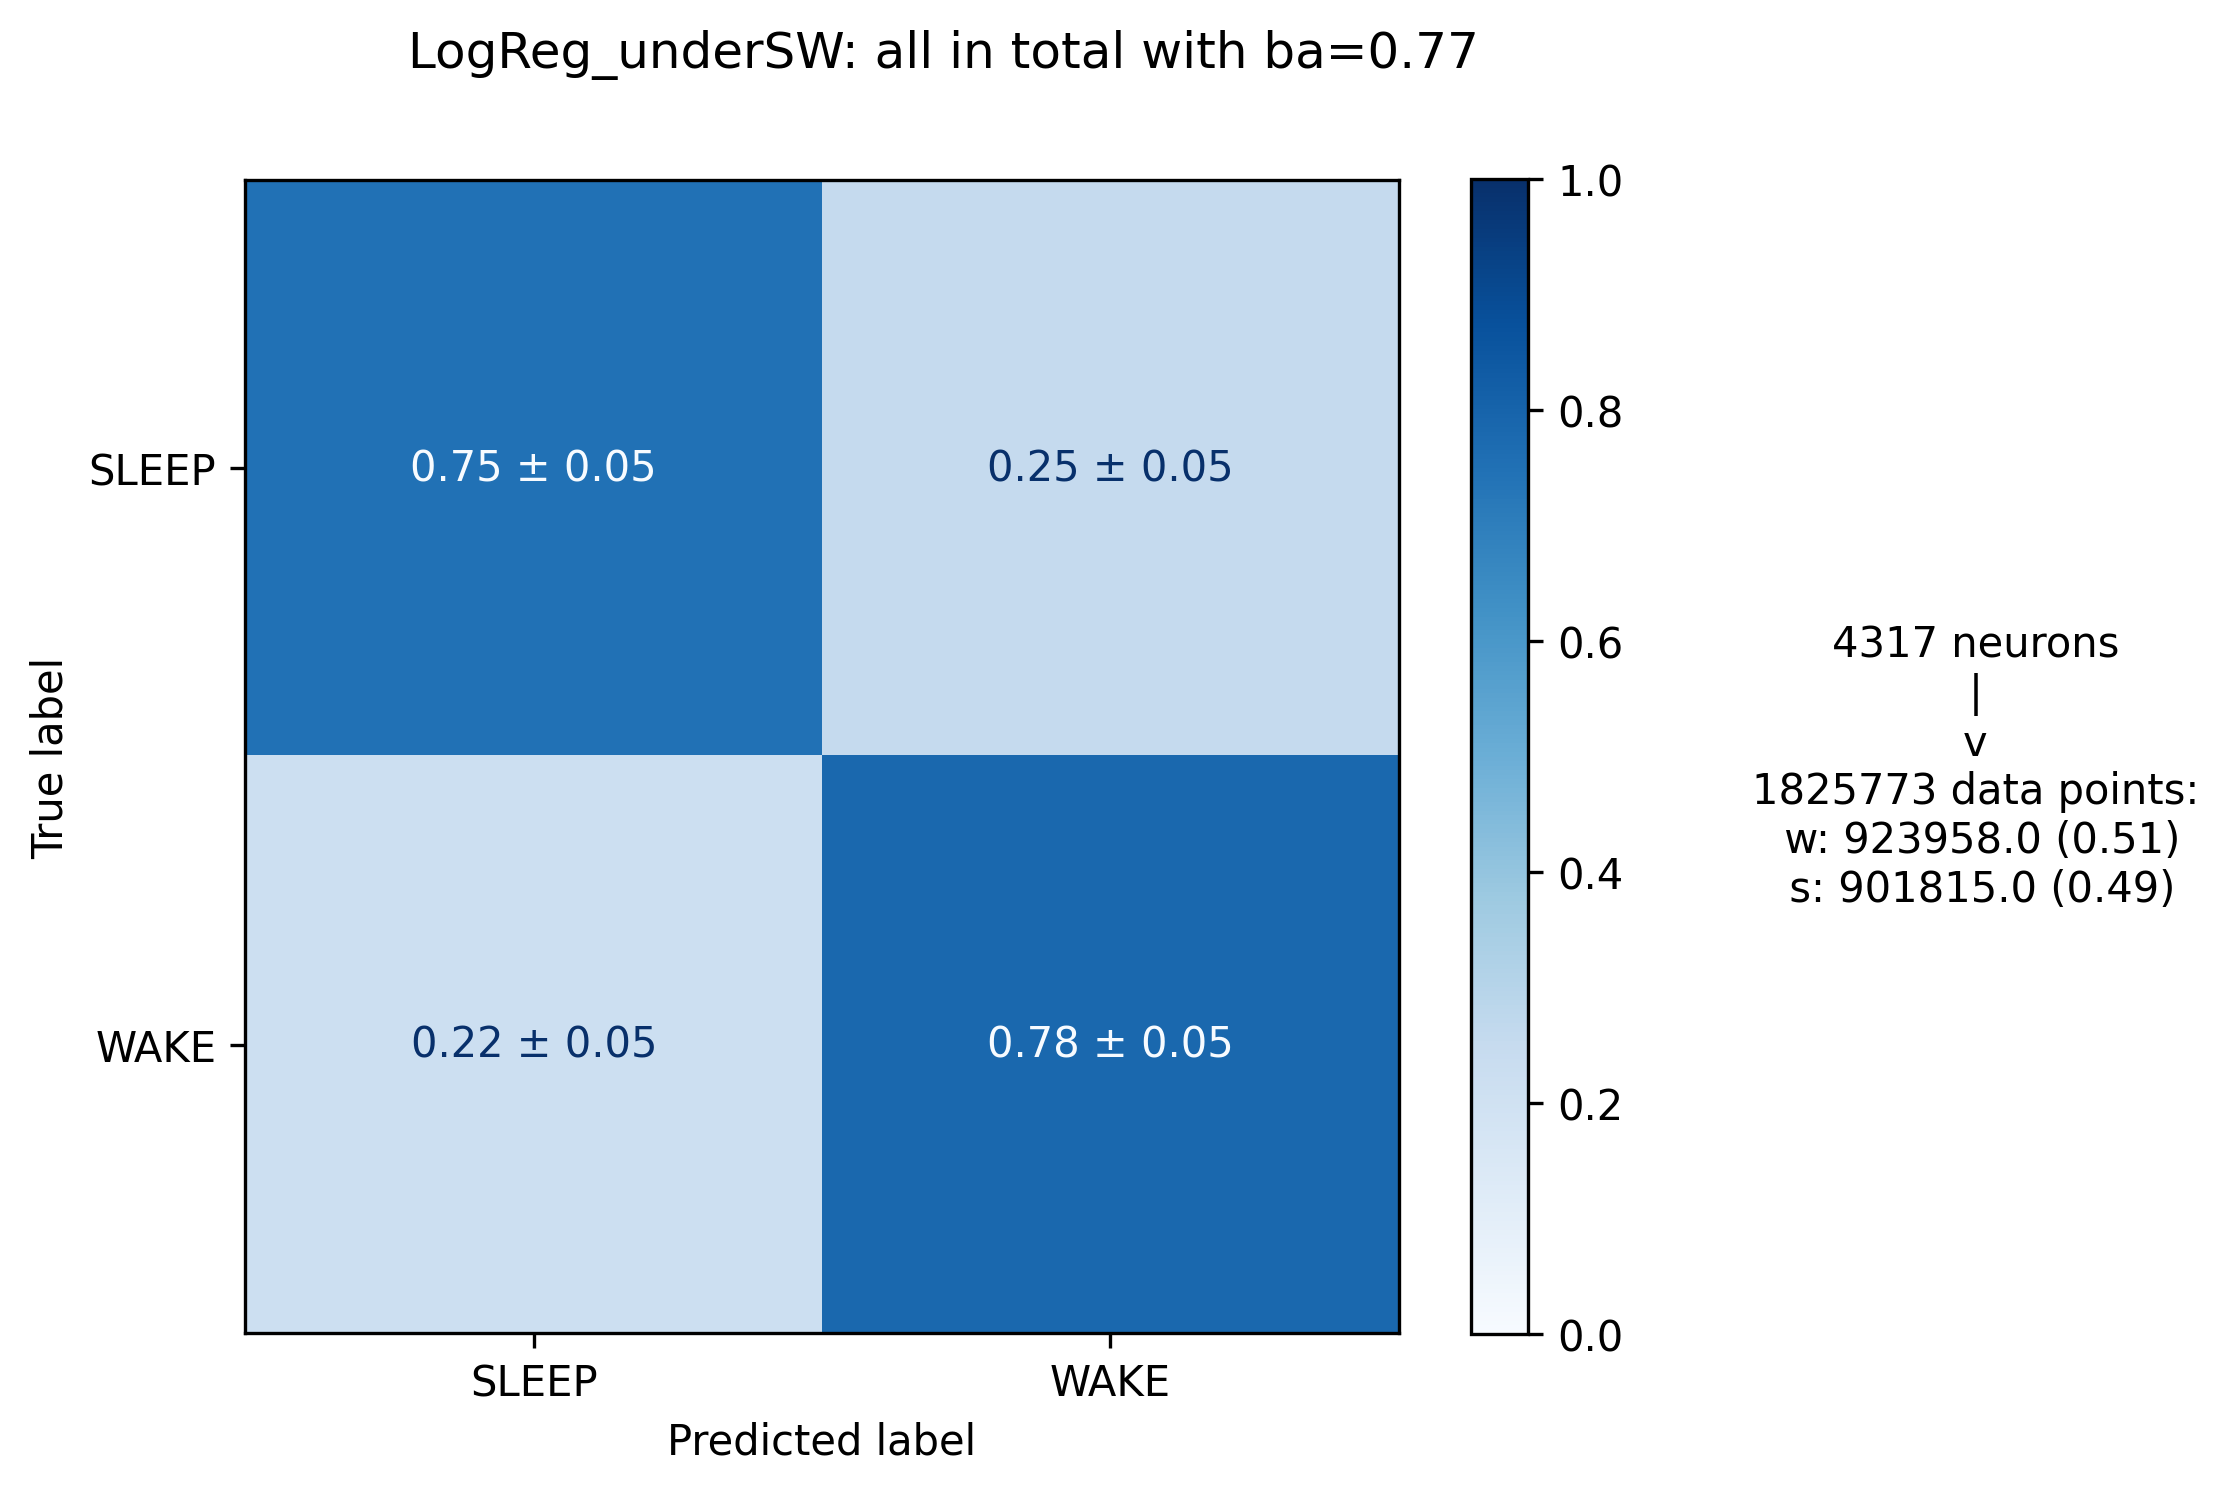

In [8]:
for model_name, matrices in sw_cms.items():
    #Specify norm_size=2 so that the visual works for 2 states
    get_mean_cms_visual(matrices, sw_train_condensed, f"{model_name}SW", subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=True, alt_se=True, norm_size=2)

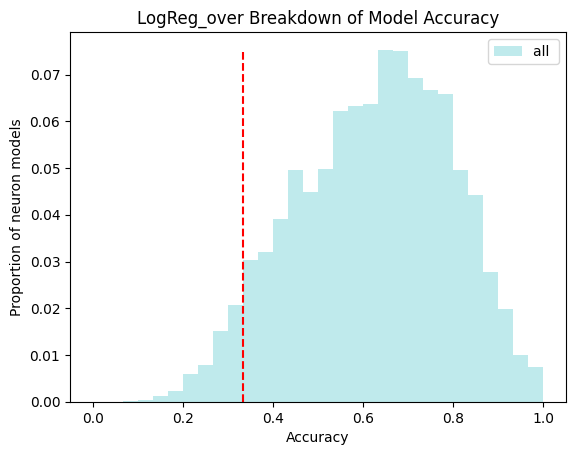

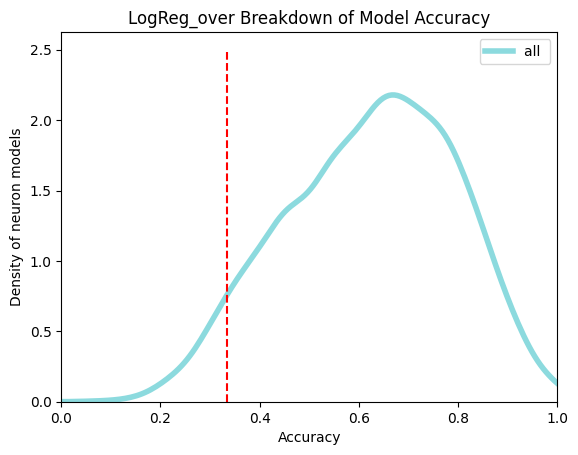

In [9]:
for model_name, matrices in cms.items():
    get_cm_distrib_hist(matrices, train_condensed, f"{model_name} Breakdown of Model Accuracy", bin_count=30)
    plt.show()
    get_cm_distrib_hist(matrices, train_condensed, f"{model_name} Breakdown of Model Accuracy", kde=True, linewidth=4)

# Examining Performances by Groupings
Now you want to get breakdowns of things by different groups. Easy! Provide to the above functions any of the following parameters: by_age, by_geno, by_region, by_ntype, or by_animal (which overrides by_age and by_geno) and either of these previous visuals will split up accordingly. Use subset{}, exclude{}, or these[] to alter which ones get generated, though generally I just generate all of them and pick the one I wanted specifically

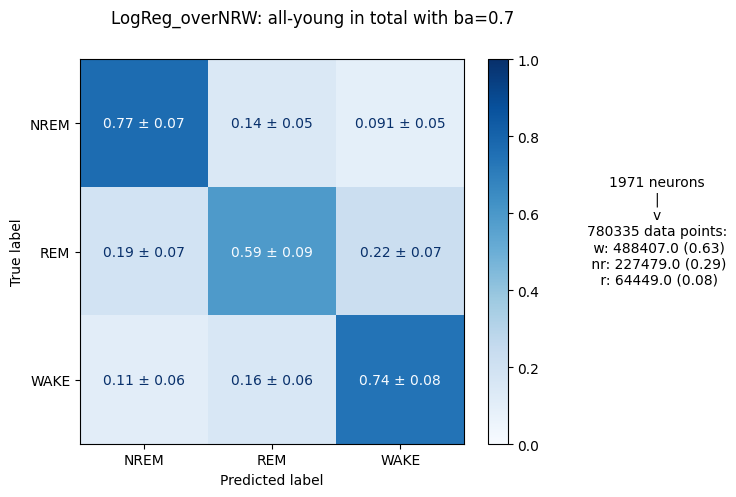

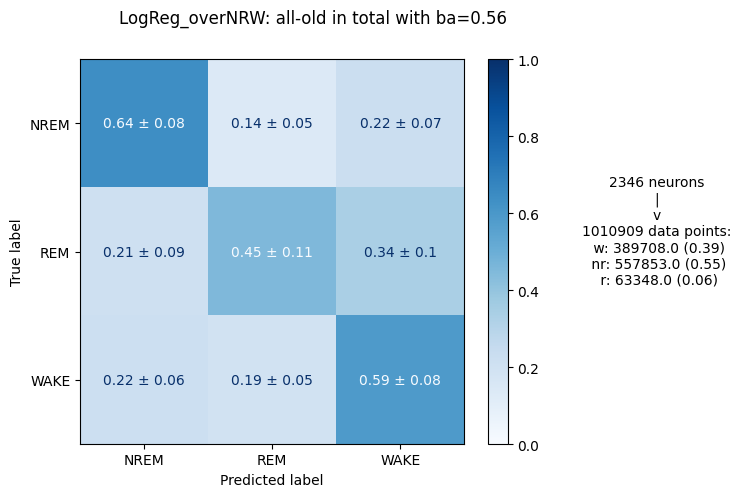

In [10]:
for model_name, matrices in cms.items():
    get_mean_cms_visual(matrices, train_condensed, f"{model_name}NRW", subplot_kwargs={'figsize':(6.2,5)}, 
                        addon_text=True, alt_se=True, by_age=True)

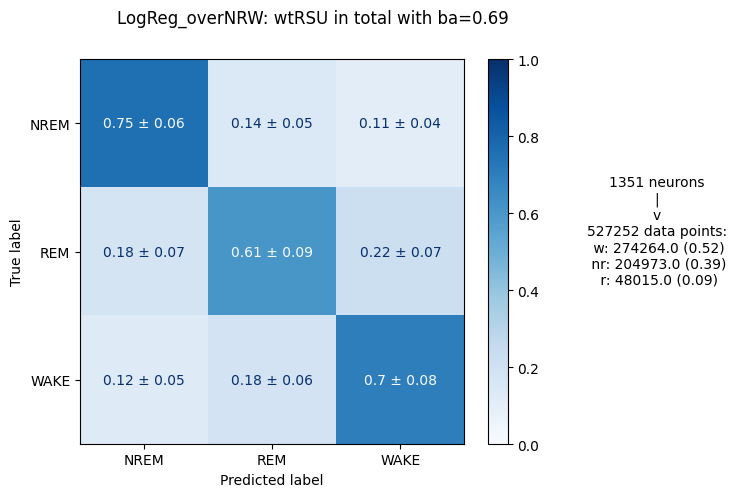

In [11]:
for model_name, matrices in cms.items():
    get_mean_cms_visual(matrices, train_condensed, f"{model_name}NRW", subplot_kwargs={'figsize':(6.2,5)}, 
                        addon_text=True, alt_se=True, by_geno=True, by_ntype=True,
                       #if you are only interested in a specific subset graph, feel free to subset or exclude things
                       #Though if you want to subset/exclude something, you need to be splitting "by" that thing already
                       #Unless you are splitting by animal, which includes geno+age inherently
                       subset={'geno':'wt', 'ntype':'RSU'})

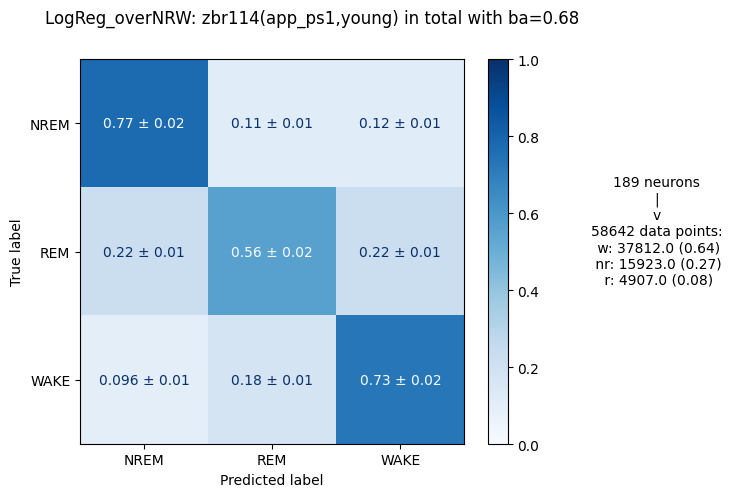

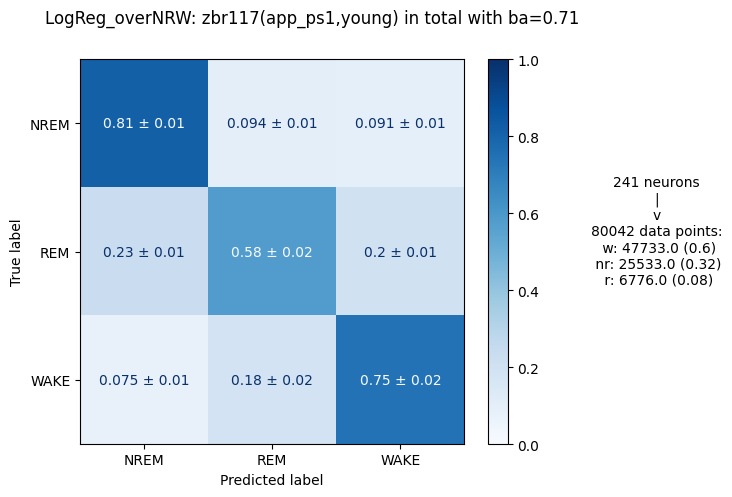

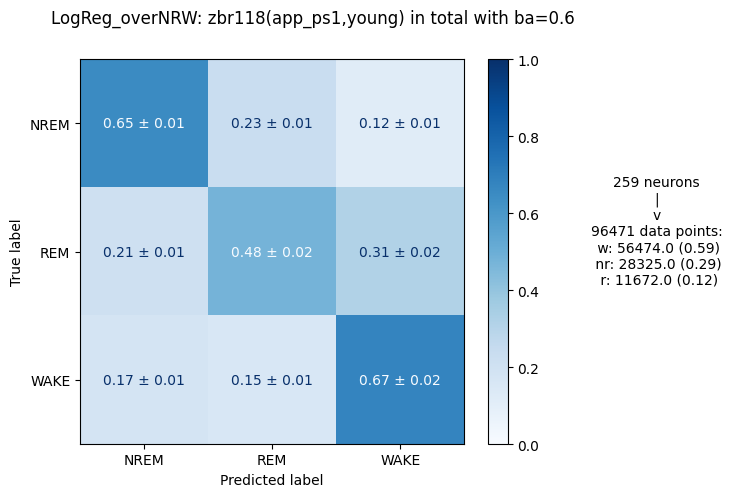

In [16]:
for model_name, matrices in cms.items():
    get_mean_cms_visual(matrices, train_condensed, f"{model_name}NRW", subplot_kwargs={'figsize':(6.2,5)}, 
                        addon_text=True, alt_se=True, by_animal=True, exclude={'geno':'wt', 'age':'old'},
                       #Get just the second-4th animal in this grouping
                       these = [1,4])

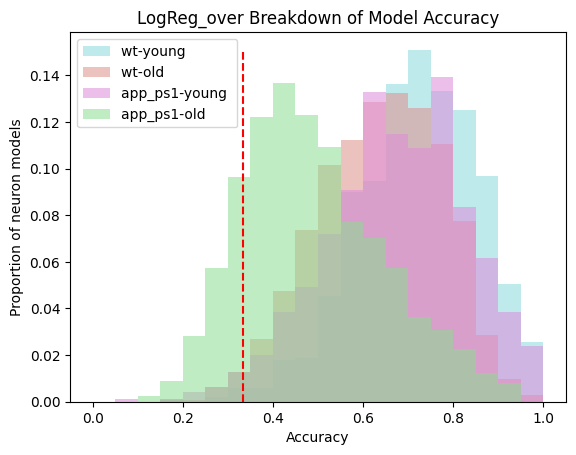

In [17]:
#Same deal for histograms
for model_name, matrices in cms.items():
    get_cm_distrib_hist(matrices, train_condensed, f"{model_name} Breakdown of Model Accuracy", bin_count=20,
                       by_geno=True, by_age=True)

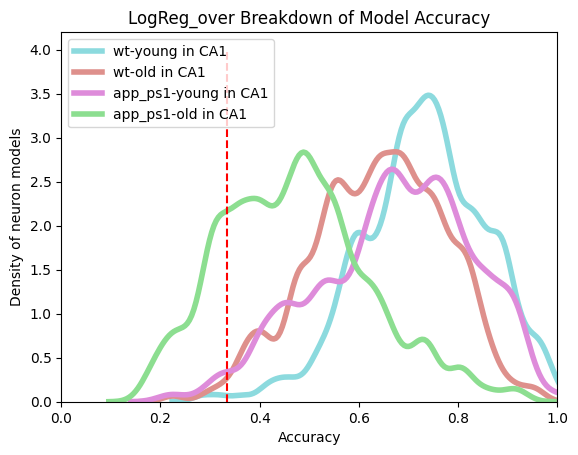

In [18]:
#Same deal for histograms
for model_name, matrices in cms.items():
    get_cm_distrib_hist(matrices, train_condensed, f"{model_name} Breakdown of Model Accuracy", bin_count=20,
                       by_geno=True, by_age=True, by_region=True, subset={'region':"CA1"}, kde=True,
                       #bw_adjust is only a param for kde plots, affects amount of smoothing, defaults to 1
                       bw_adjust=0.5, linewidth=4)

# Investigating Bout Distribution Data
Get a nice dataframe that looks at whatever groupings you want and gets you collected stats on how many chunks there are of each within the trainiing dataset. In this example, I first group it all by animal to get counts per animal, then sort it into the four age/geno groups for the display

In [19]:
df = get_state_grouping_dataframe(train_condensed, grouping_vars={'by_animal':True}, just_counts=False)

In [20]:
arrs = []
for geno in ['wt', 'app_ps1']:
    for age in ['young', 'old']:
        arrs.append([*zip(*list(df[(df.age==age)&(df.geno==geno)].counts))])

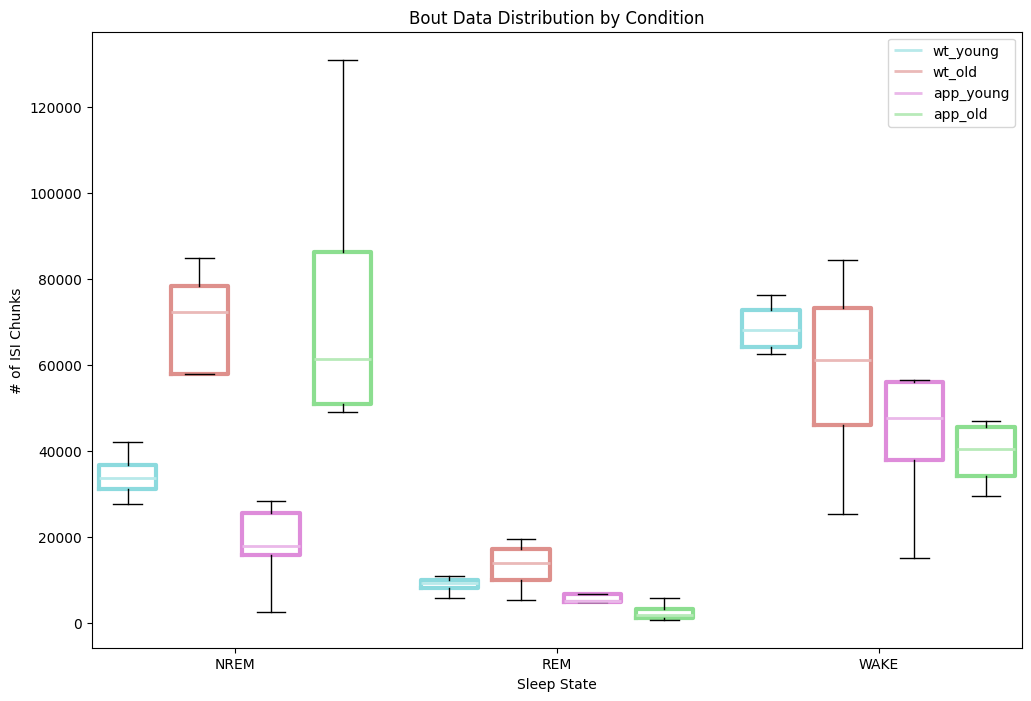

In [21]:
#The box_whisker plot function is super helpful for splitting arrays by internal groupings and reorganizing them in a ton
#of ways, look at the documentation in graphical_functions.py
plots, poses = box_whisker(*arrs, labels=['NREM', 'REM', 'WAKE'], output=True,
                          color_by_group=False, showfliers=False)
plt.ylabel('# of ISI Chunks')
plt.title('Bout Data Distribution by Condition')
plt.legend([boxplot['medians'][0] for boxplot in plots],['wt_young', 'wt_old','app_young', 'app_old'])

# Doing Anything With MLP
This is sort of difficult and a hassle, but manageable! You don't need to scale data to get metrics like the other models, but you do need to generate the log distribution

In [2]:
#You can still do all the varied downsampling shenanigans you might want, just add early_train_exit to prevent it from
#scaling the train/test data for no reason and wasting your time
split_thres = (0.4, 0.6)
addon='unfiltered'
#early_train_exit specifies that you just want the train/test distribution, without added scaled features of the distribution,
#which isn't necessary for MLP stuff since it is trained directly on the distribution itself.
train, test= generate_train_test_dataset(split_thres, addon, early_train_exit=True)

Loading Dataset
adding column if necessary
Filtering out lame neurons
Splitting into train/test 500 isi chunks


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [00:49<00:00, 87.47it/s]


Add in some ids
minimizing stuff in the train dataset
Not filtering the dataset/downsampling isis, assuming this is intentional!


### Obtain the log ISI distribution for the train/test set

In [3]:
start_val,stop_val,bin_size = 0.0015,3,0.01 #in seconds
isi_bins = np.arange(start_val,stop_val,bin_size)
N_BINS = 100
BIN_EDGES = np.logspace(np.log10(0.001), np.log10(60), N_BINS + 1)
def obtain_distribution(unit_isi, log_spaced=True):
    if not log_spaced:
        unit_isi_distrib, _ = np.histogram(unit_isi, isi_bins, density=False)
    else: unit_isi_distrib, _ = np.histogram(unit_isi, BIN_EDGES)
    
    if unit_isi_distrib.sum()!=0: #min max normalization
        unit_isi_distrib = (unit_isi_distrib-np.min(unit_isi_distrib))/(np.max(unit_isi_distrib)-np.min(unit_isi_distrib))
    
    return unit_isi_distrib
    
tqdm.pandas()
train['isi_distrib'] = train[f'isi'].progress_apply(obtain_distribution)
test['isi_distrib'] = test[f'isi'].progress_apply(obtain_distribution)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 502898/502898 [00:18<00:00, 26875.38it/s]


In [4]:
#Remove any nans (though there shouldn't be any)
arrs = [train, test]
for i in range(len(arrs)):
    arrs[i]['nan_m'] = arrs[i].isi_distrib.progress_apply(lambda x: np.any(np.isnan(x)))
    arrs[i] = arrs[i][~arrs[i].nan_m]
    arrs[i] = arrs[i].drop(columns='nan_m')
    arrs[i] = arrs[i].reset_index(drop=True)
train, test = arrs

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 502898/502898 [00:01<00:00, 255944.36it/s]


In [34]:
#Run the actual per-cell training, saving two backups of the cms in mlp_cms in backup_baseline and baseline.pkl,
# since it takes so long. Makes it resilient to stops+starts. Once complete, copy the cms into a new descriptive folder
#If cms are already in the baseline/backup files, delete them once you have ensured they are saved in a different file
cms = load_safe()
i = 0
print(f"Loaded {len(cms)} confusion matrices from storage")
for cell in tqdm(train.cell.unique()):
    if cell not in cms:
        i+=1
        #before = time.time()
        item = mlp_individual(cell, train, sampling_type='under')
#         if not len(item):
#             print("SMOTE must have failed, just do oversampling instead, proceed")
#             item = mlp_individual(cell, train, sampling_type='over')
        if not len(item):
            print("Skip this chump")
            continue
        #after = time.time()
        #print(f"This model took |{after-before} to train, had {item['training_length']} to go through")
        if item['model'].interrupted:
            print("Oh training got interrupted, exit!!!")
            save_safe(cms)
            break
        cm = get_individual_cm(item, test, get_spiking=True, use_spike_matrix=False)
        if not len(cm):
            print("This cm failed somehow, bypassing")
            continue
        cms[cell] = cm[cell]
        if not i%5:
            save_safe(cms)

Successfully loaded the main cm dictionary
Loaded 3206 confusion matrices from storage


  0%|                                                                                                                           | 0/4317 [00:00<?, ?it/s]

Trying resampling
Hey this is tragic, this neuron doesn't have all three states, won't work :(
Skip this chump
Trying resampling
trying training


/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
 74%|█████████████████████████████████████████████████████████████████████████████████▋                            | 3208/4317 [00:01<00:00, 2937.36it/s]

Trying resampling
trying training


...

/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████▉| 4315/4317 [19:24<00:01,  1.48it/s]

Trying resampling
trying training


/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████▉| 4316/4317 [19:28<00:01,  1.67s/it]

Trying resampling
trying training


/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:262: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [19:28<00:00,  3.69it/s]


In [21]:
train_condensed = get_extended_condensed_data(train)

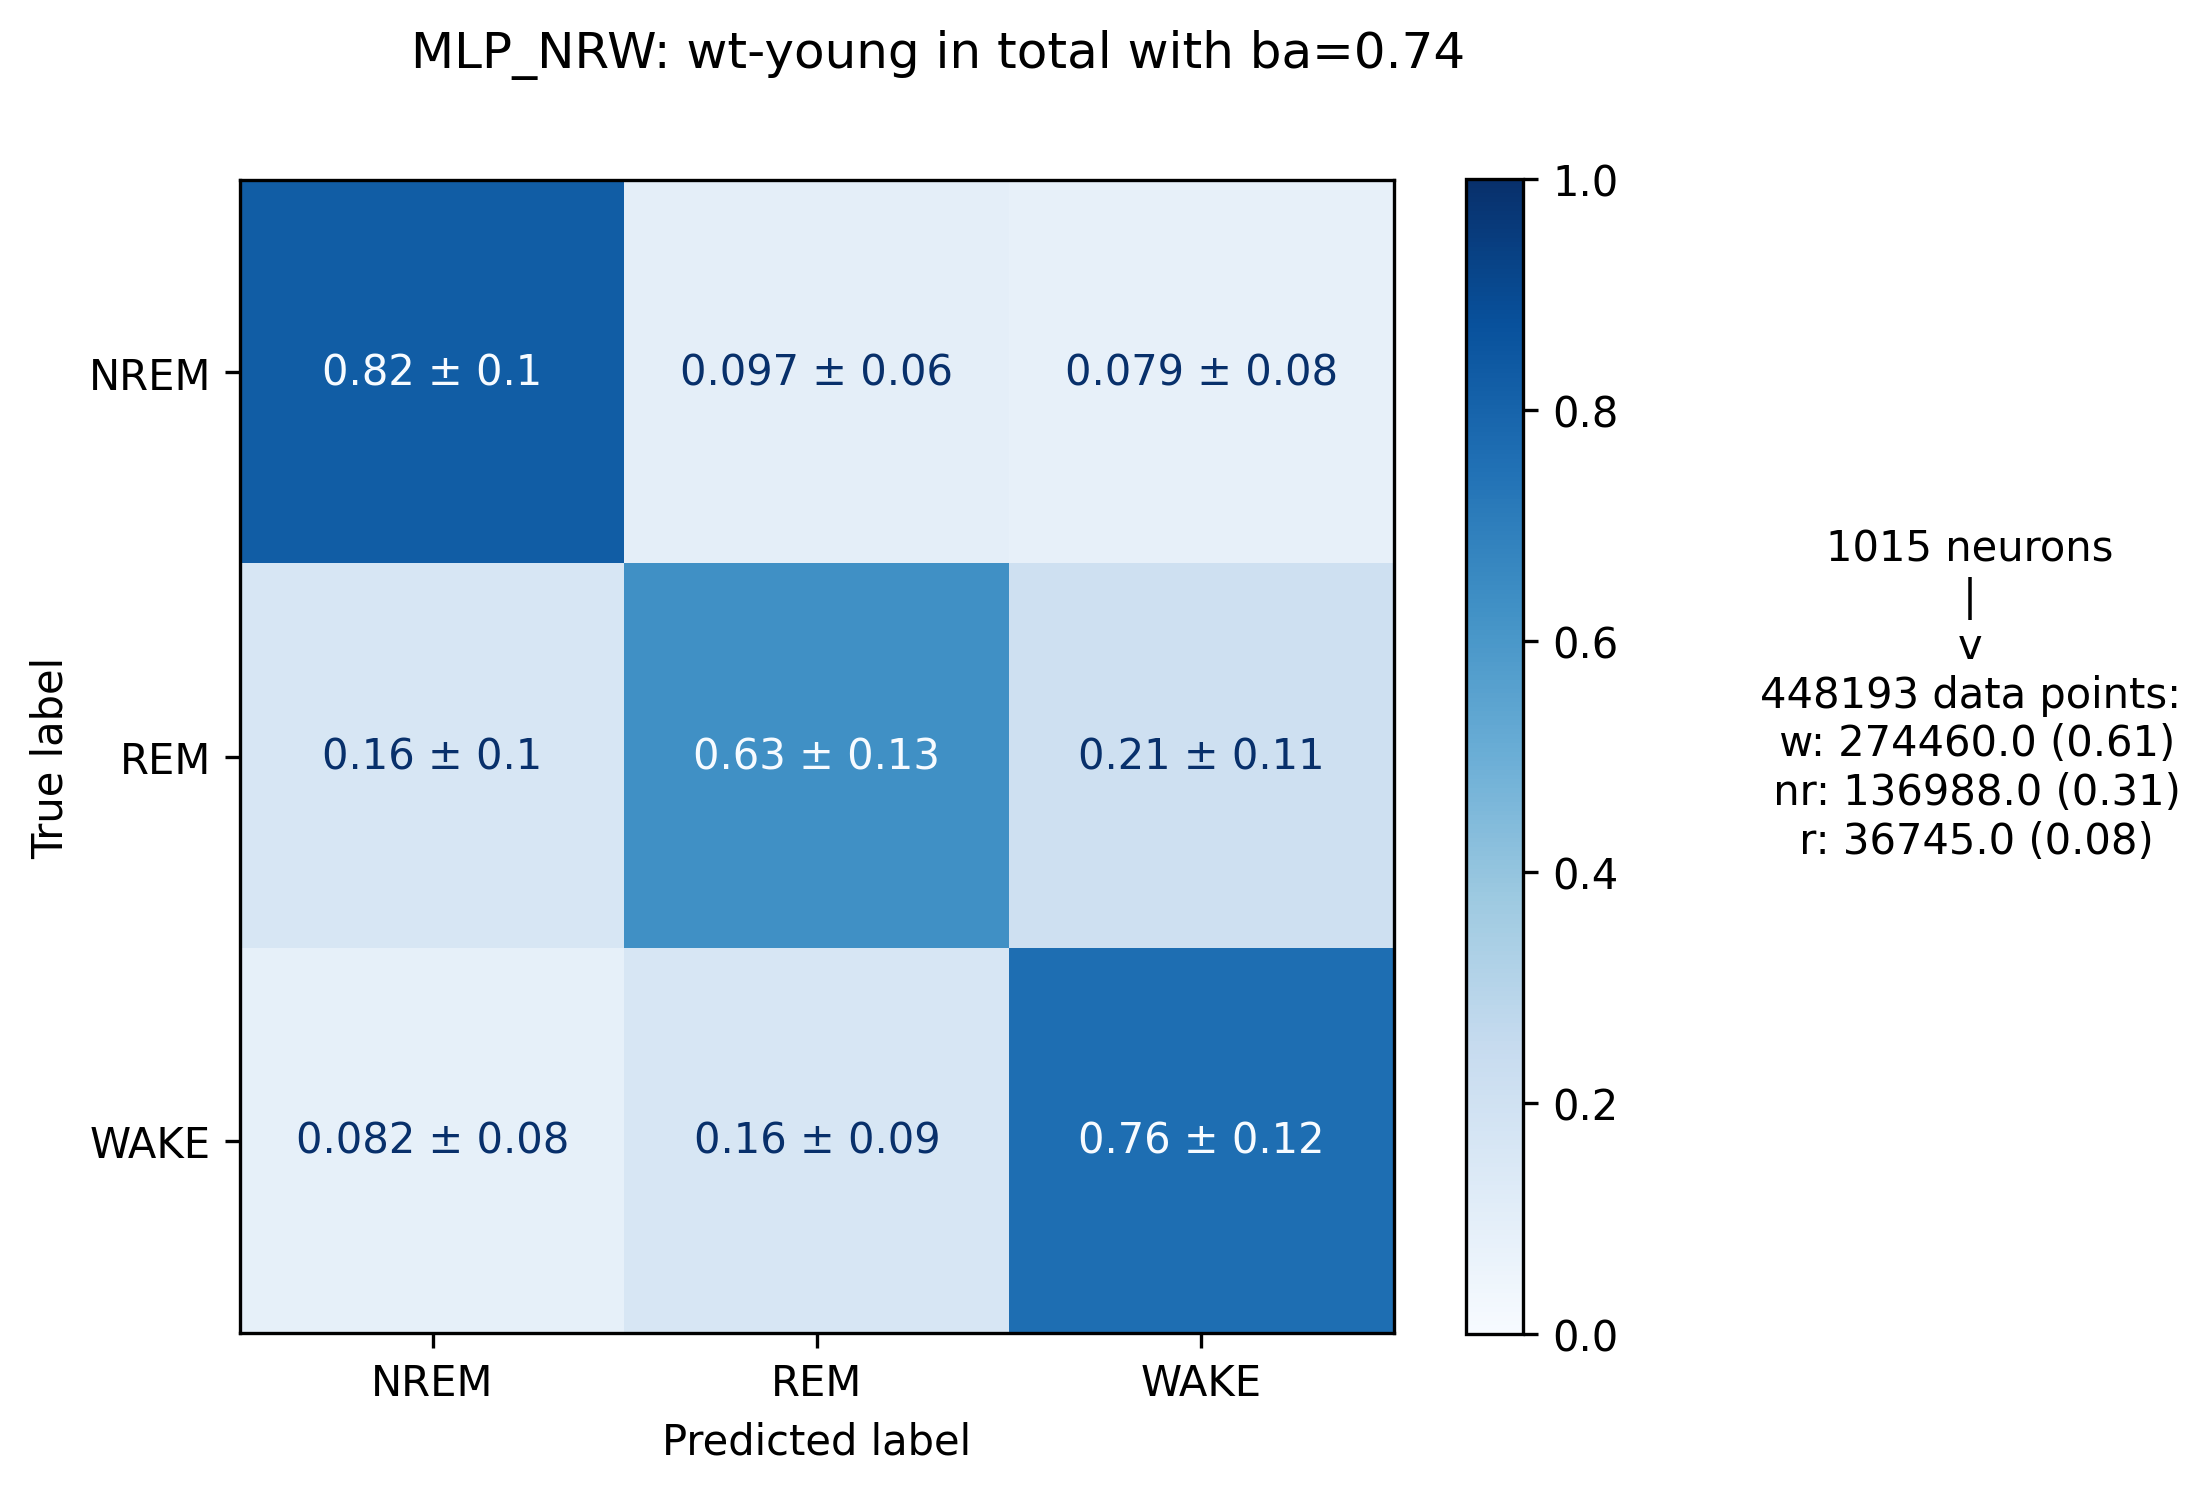

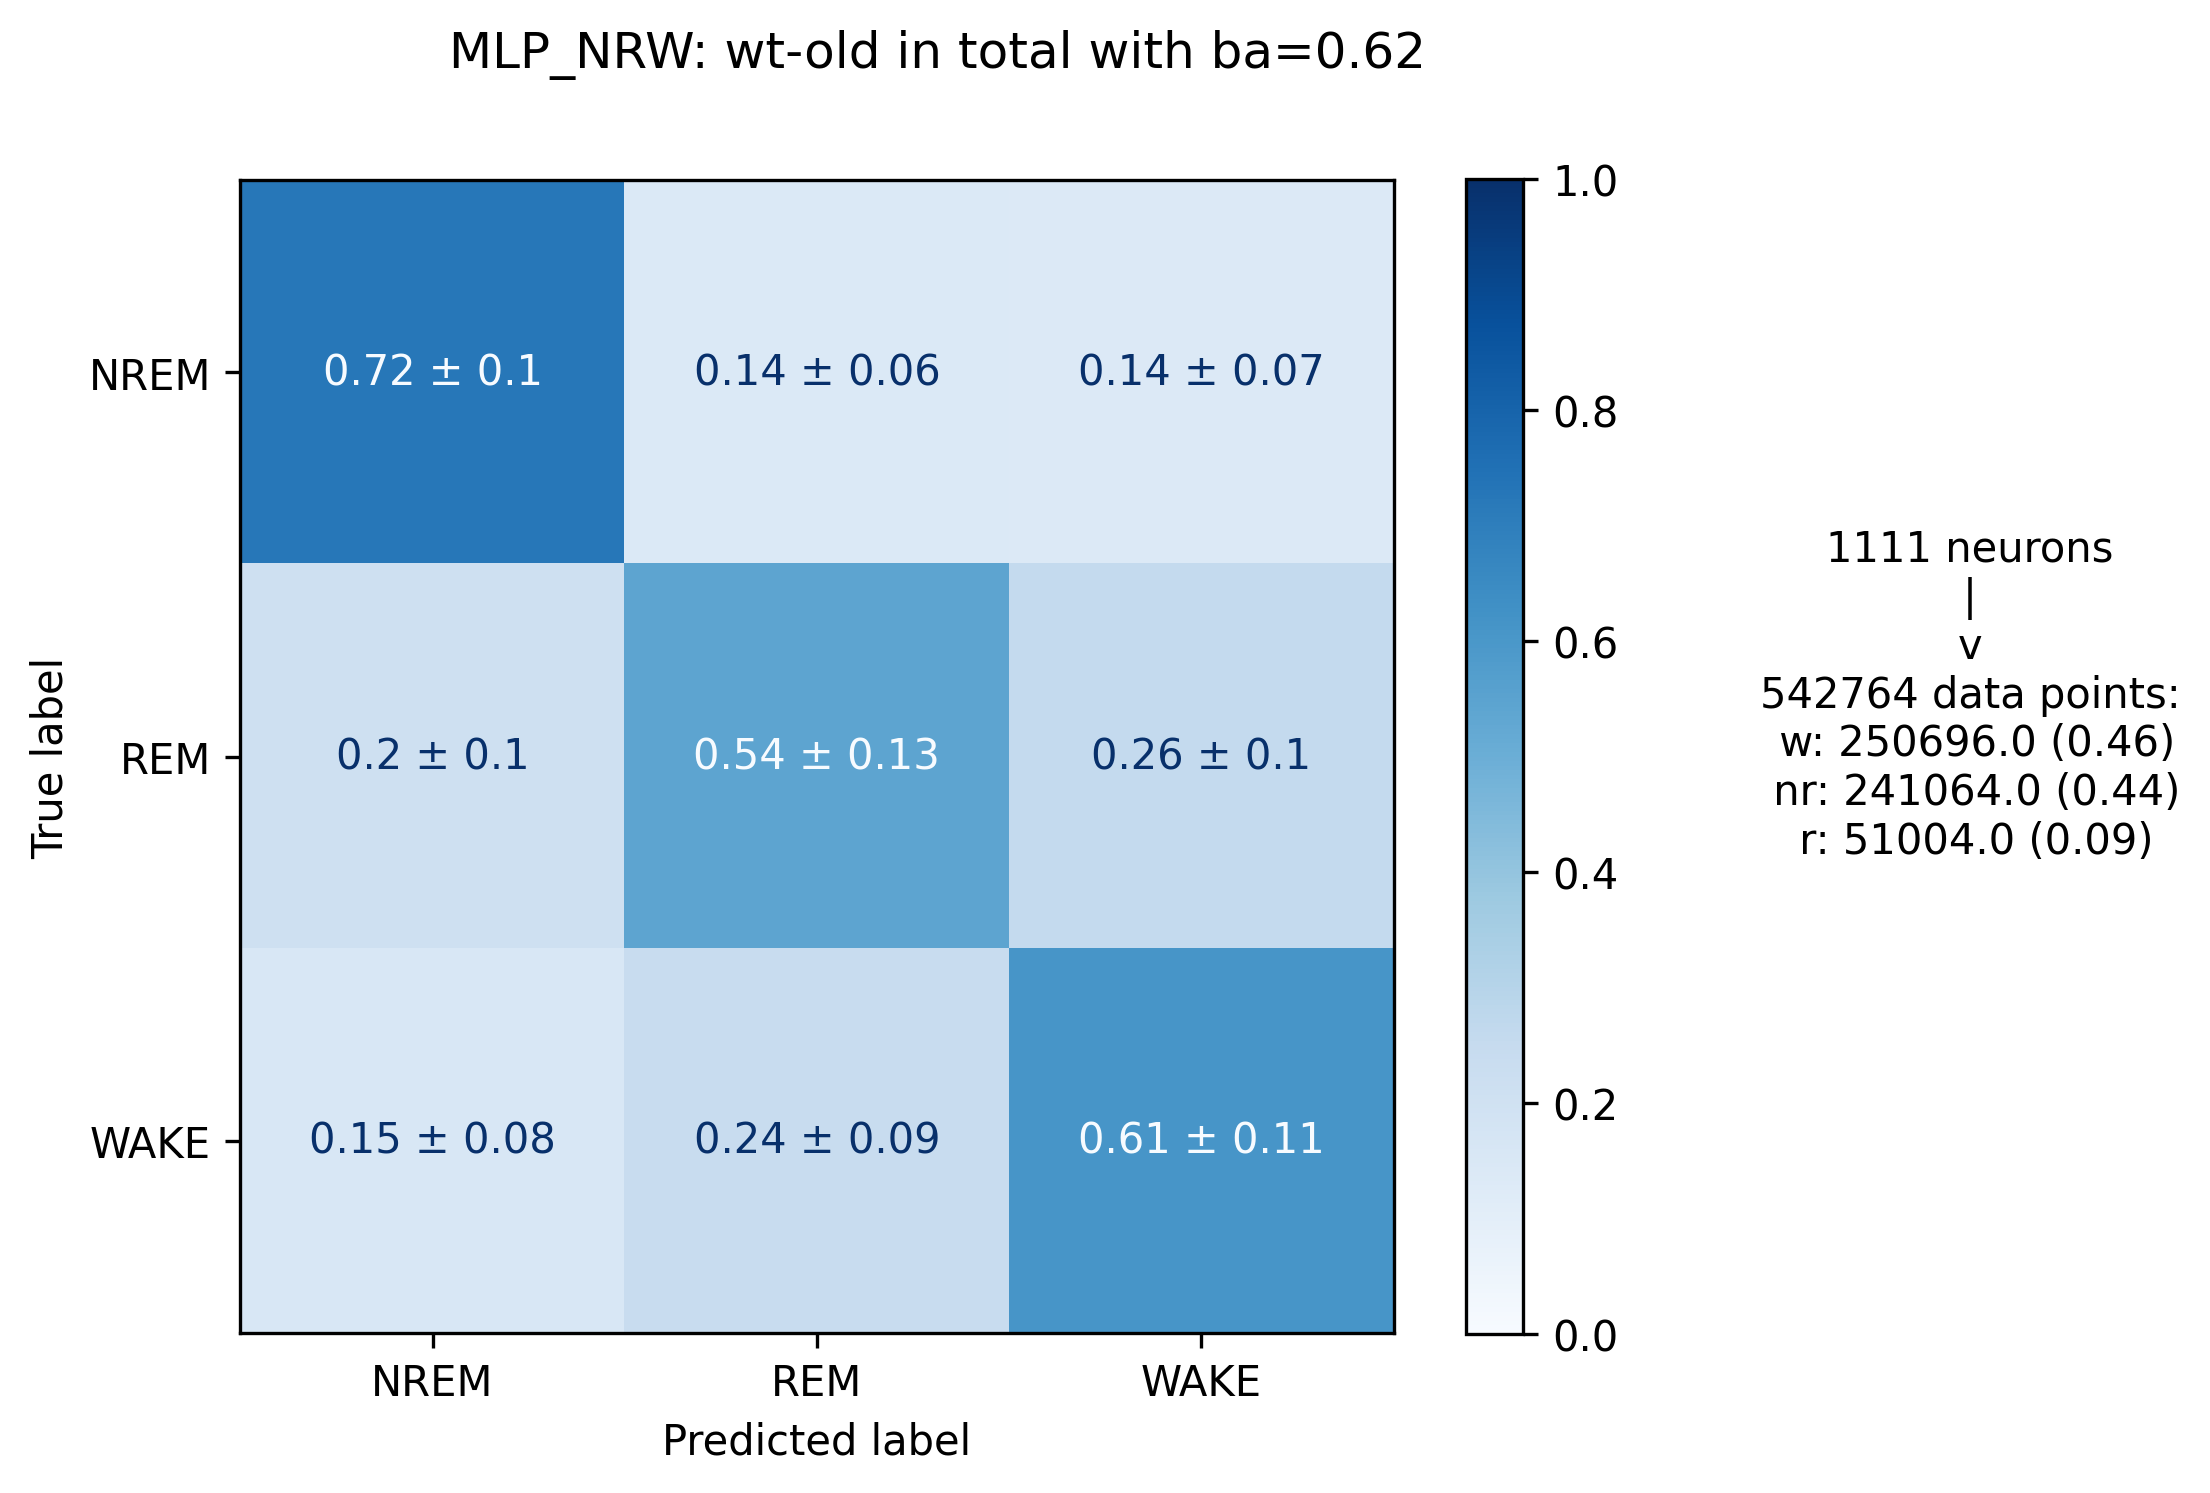

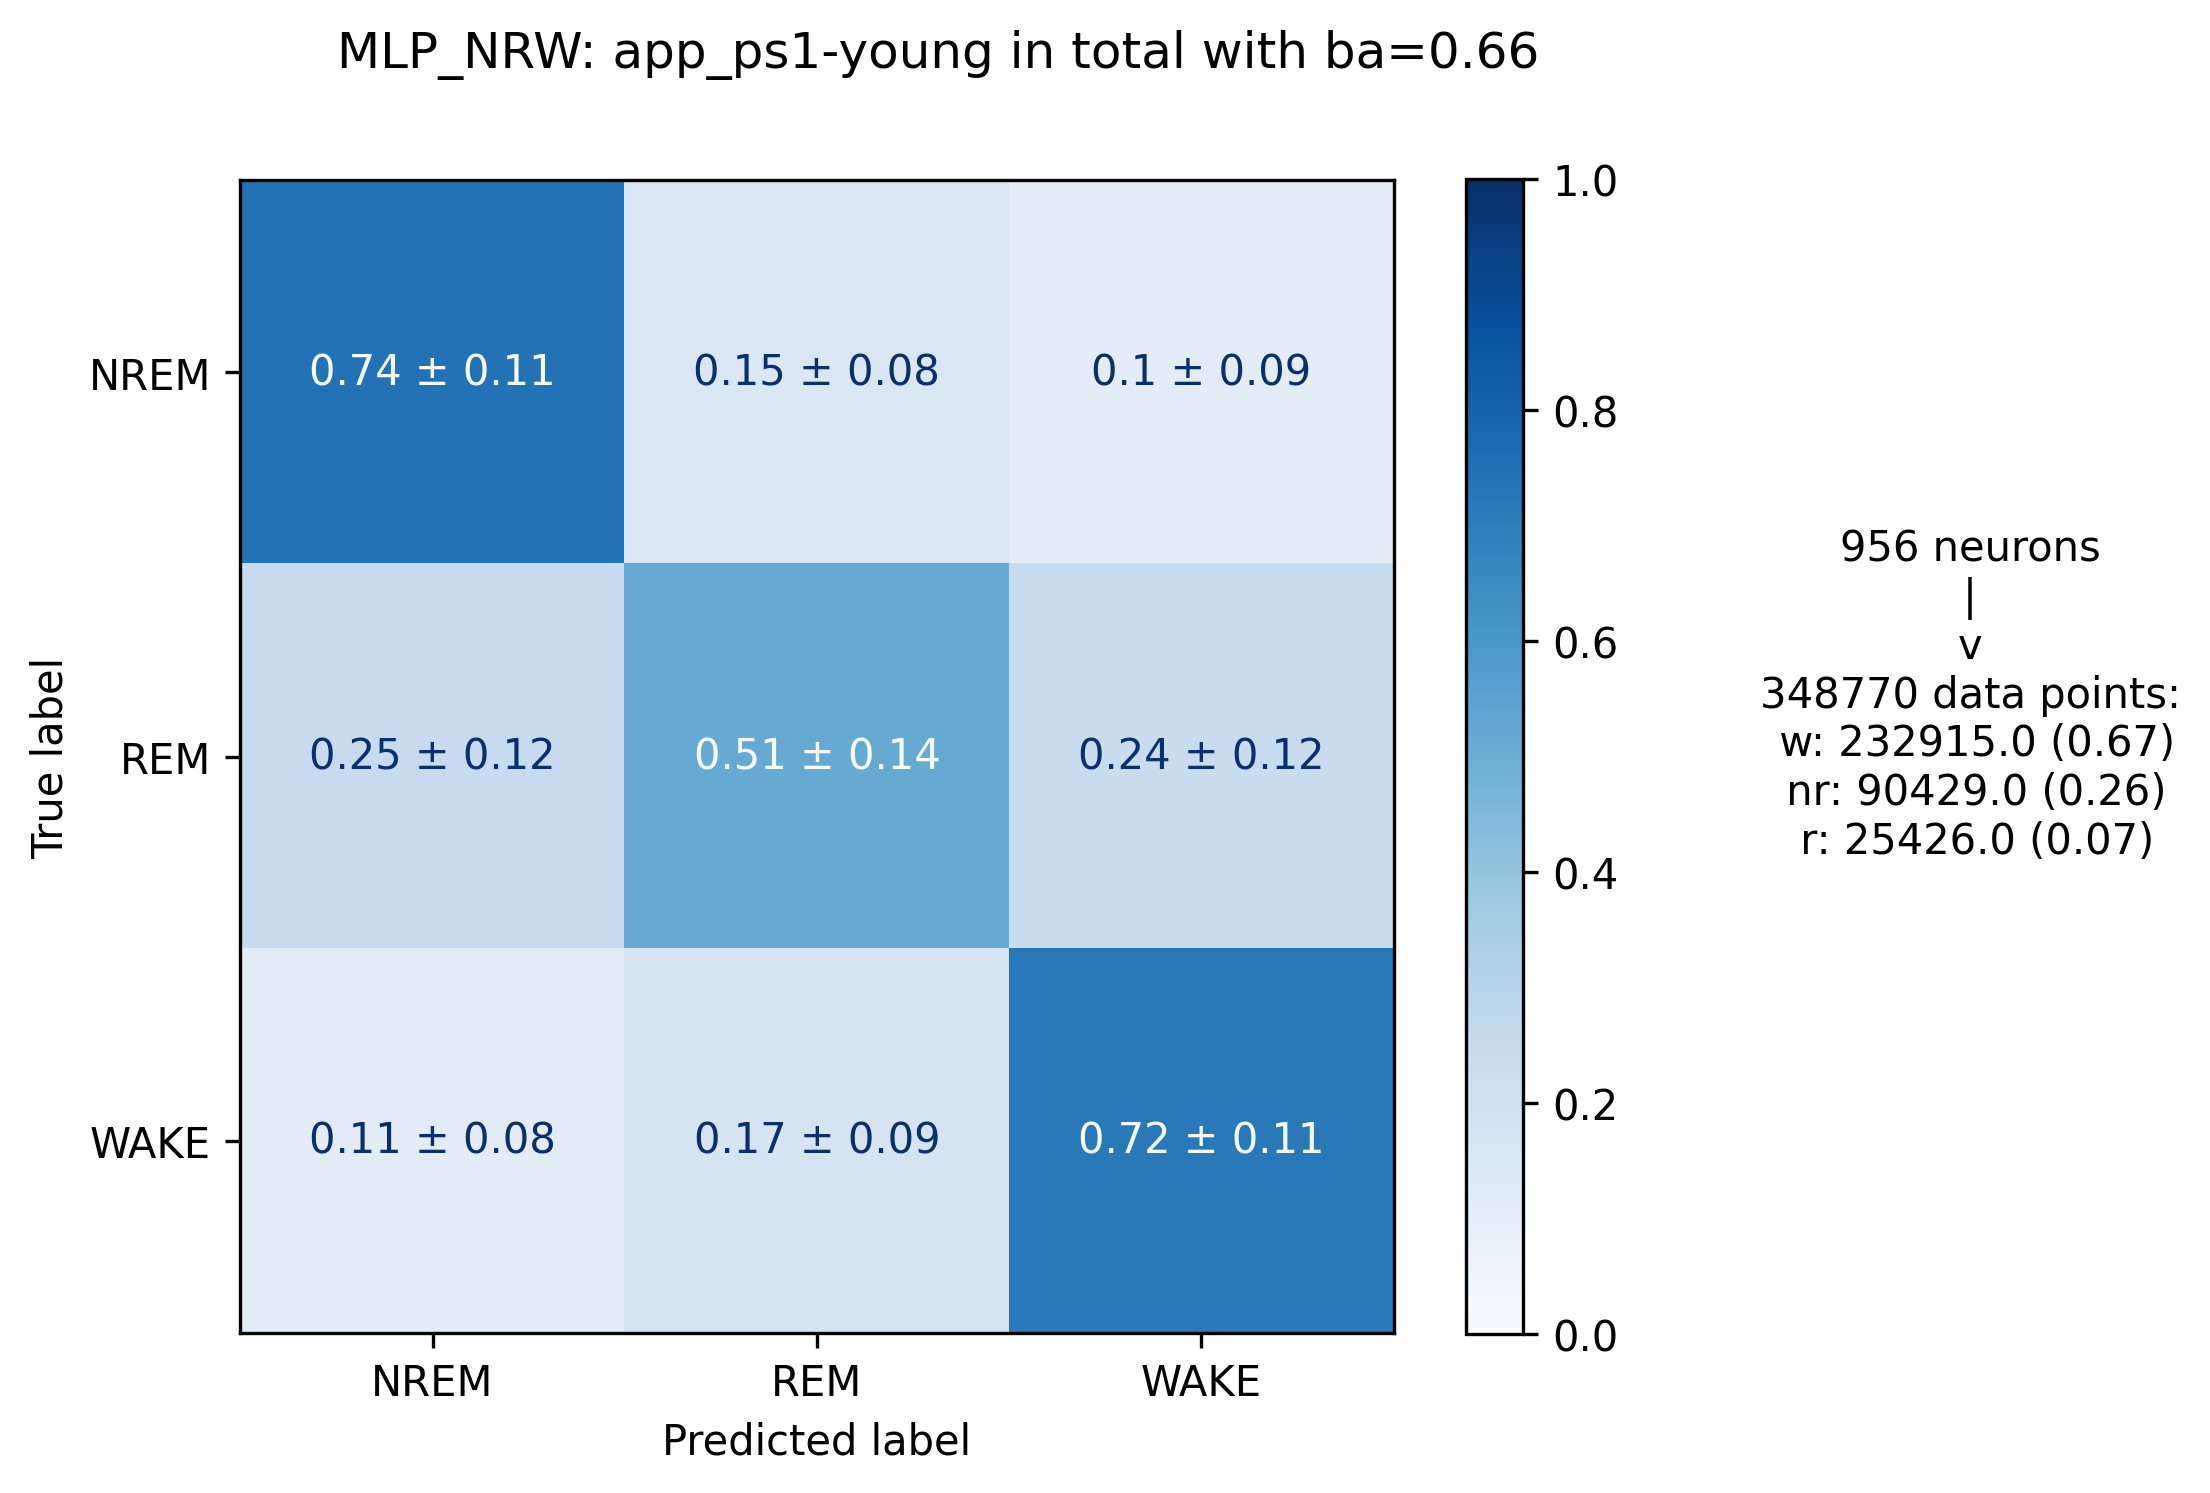

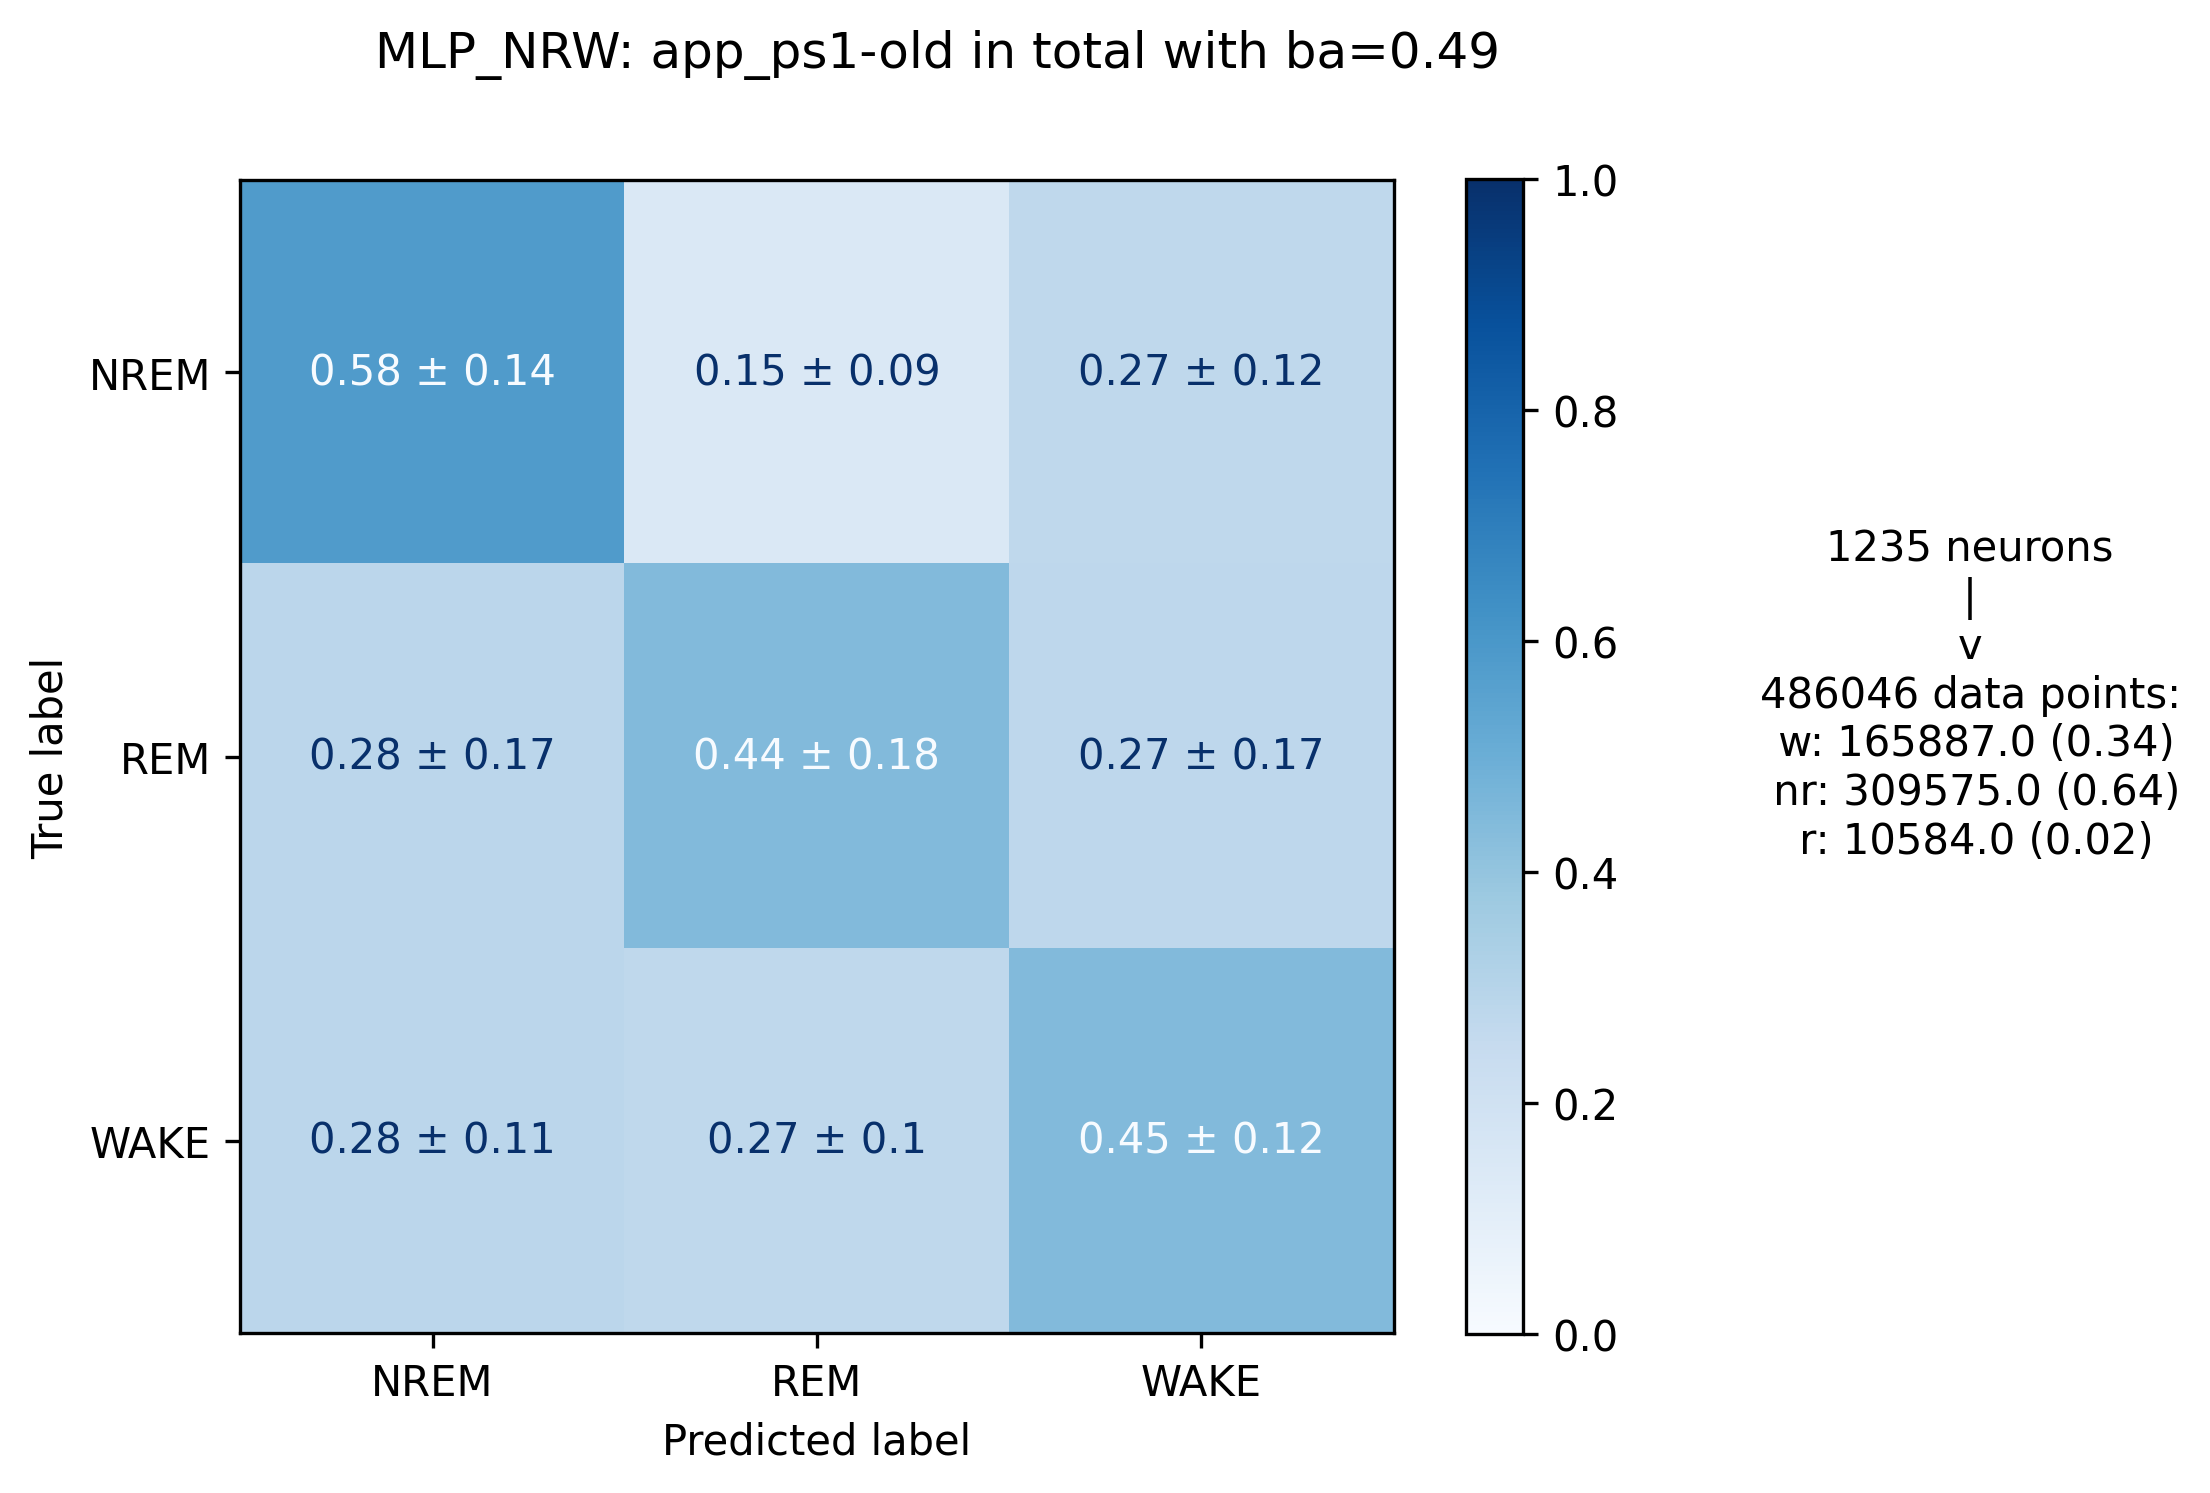

In [37]:
get_mean_cms_visual(cms, train_condensed, f"MLP_NRW", subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=True, alt_se=True, by_age=True, by_geno=True)

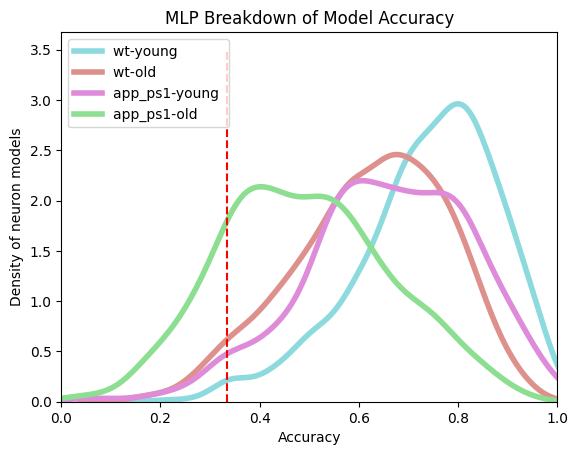

In [42]:
get_cm_distrib_hist(cms, train_condensed, f"MLP Breakdown of Model Accuracy", bin_count=20,
                   by_geno=True, by_age=True, subset={}, kde=True,
                   linewidth=4)

# Messing with Grouping/Held Out Stuff  --\\_ (*~ *)_/-- , bit harder
There are two relevant things you need to look out for:
1. How you are grouping/splitting the train/test dataset
2. How you are grouping the models that are being trained on that dataset

In [ ]:
#Example code for testing held-out neurons by animal 80/20
split_thres = (0.2, 0.4)
addon = 'unfiltered'
starting_from = 0
grouping_vars = {"by_animal":True}
load_data=False
#Please never put save_data_after as true, that will overwrite legitimate by neuron models. Just wait, or
#bug me to make the file system account for grouping/filtering differences
train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, downlims,
                                                         starting_from=starting_from,
                                                          #Vital dictionary here, dictating that the 80/20 split
                                                          #should occur by *group*, and that those groups are a pure
                                                          #by_animal split. These grouping vars can be any of the
                                                          #by_geno, by_age, by_ntype from before/combination of them
                                                          #If this dictionary is empty (default), it goes to per-neuron 
                                                          #splitting
                                                          grouping=grouping_vars,
                                                         save_data_after=False)
#This code is meant to make the model and cms gathering easy, since it recontextualizes
#the condensed dataset so the 'label' column is the group label, and that becomes the 
#relevant grouping parameter for training and cm gathering
graphic_train = get_extended_condensed_data(train_scaled)
groupings, group_labels, _, _, _, _ = get_cell_groupings(graphic_train, **grouping_vars)
def replace_with_label(cell):
    for i,group in enumerate(groupings):
        if cell in group:
            return group_labels[i]
    return ""
graphic_train['label'] = graphic_train.cell.apply(replace_with_label)
graphic_train = graphic_train.drop_duplicates(['label'])

#Then, pass in the grouping variables to the model training step so that each group is trained on by 1 model,
#using LogRegGroup as the method. The other ones (xgb_by_cell, log_by_cell), will give you nonsense since
#they look at the 'cell' column for identifiers when duplicate labels were dropped already
#Note that you can use LogRegGroup here with any parameters if the original dataset was split by neuron,
#(which effectively gives you groupings that look at 80% of all neuronal data from the specific group for training,
#with no held-out neurons)
#but that if there
#are grouping variables for the initial dataset you have to match them here (in order to have proper held-out neurons 80/20).
models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogRegGroup'], **grouping_vars)
cms = get_cms_multi(test_scaled, models, get_spiking=True, grouping_vars=grouping_vars)

# Trying Majority Vote by Animal
This is kind of a pain, but doable since the pain is all behind the scenes now. All you need to do is provide the models and cms with timing information included and you are good to go. Should work for any model, since all they are used for is as an unique identifier. This only works for 3 state predictive stuff right now, because I haven't gotten around to 2 state.

In [12]:
combined, anim_cms = get_all_animal_accuracy(nrw_models['LogReg_over'], cms['LogReg_over'], train_condensed,
                                             time_correction_by_file=True, time_norm_animal=True, interval=0,
                                            min_predictions_to_include=4)

 47%|███████████████████████████████████████████████████████                                                              | 8/17 [00:06<00:07,  1.24it/s]

lol zbr106_101_0223_0_12_28_wt sucks, skipping


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:09<00:00,  1.74it/s]


In [14]:
#Get a grouping condensed thingy that will work with the by_animal cms
condensed = train_condensed.copy()[['animal', 'geno', 'age_group', 'age']].drop_duplicates(['animal'])
condensed['cell'] = condensed['animal']

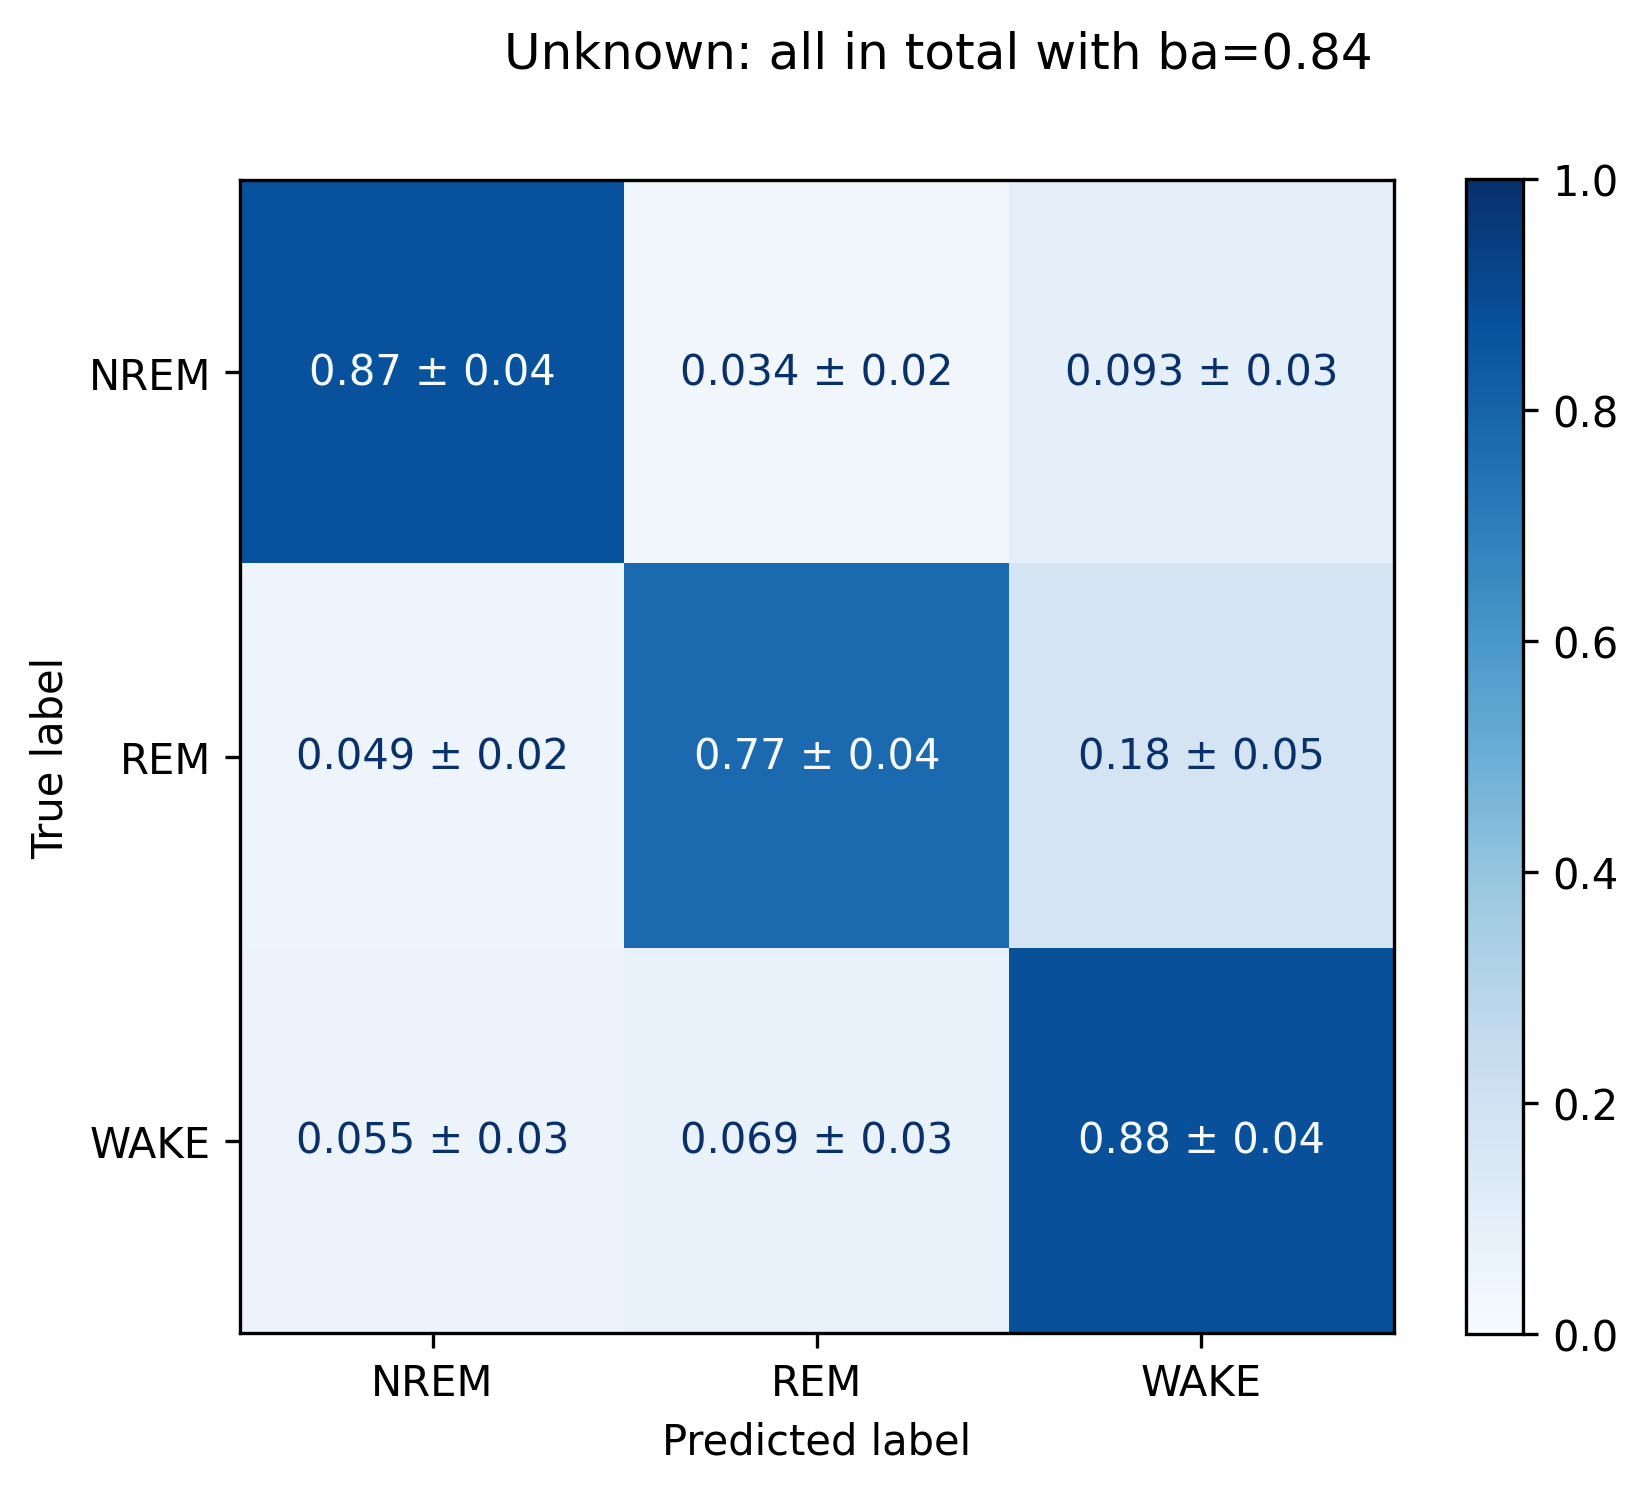

In [18]:
#Get visuals as you please, just don't try anything by region or by neuron type since that won't work as this is by animal,
#including all regions and neuron types from the animal. If you want that kind of split, you need to edit the initial train/test
#dataset by passing in additional filters to the "obtain_train_test_scaled_data" initial call to filter down the dataset
#to your specific neurons/regions of interest
get_mean_cms_visual(anim_cms, condensed, addon_text=False, by_geno=False, by_age=False, by_animal=False,
                   alt_se=True,subplot_kwargs={'figsize':(6.2,5), 'dpi':300})

### Save a dataframe to do R analysis
This is all you need, just change save and the name to something unique

In [ ]:
arr = merge_accuracy_neuron(sw_cms['LogReg_over'], sw_train_condensed, num_state=2, save=False, name='sw_logreg_under')
#or
arr = merge_accuracy_neuron(cms['LogReg_over'], train_condensed, num_state=3, save=False, name='logreg_under')